# Financial-statement page classifier

Indian bank and NBFC annual reports run to 250–700 pages, but credit review needs only a handful of them: the **profit & loss statement** and the **balance sheet**. This notebook shows a small neural network that reads the text of a page and says which of three kinds it is:

| Class | Meaning |
|---|---|
| `pnl` | Statement of profit and loss / profit and loss account (including its continuation page) |
| `balance_sheet` | Balance sheet / statement of financial position (including its continuation page) |
| `other` | Everything else: narrative, notes, schedules, auditor's report, cash flow, … |

The notebook runs top to bottom. It loads the saved model by default; set `RETRAIN = True` to train it again (about two minutes on a laptop CPU, same result every time because the random seed is fixed).

In [1]:
import json, os, pickle, subprocess, sys, warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # keep TensorFlow start-up noise out of the output
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "ann" else Path.cwd()   # works from ann/ or the project root
ANN, DATA, MODEL = ROOT / "ann", ROOT / "ann" / "_data", ROOT / "ann" / "model"
sys.path.insert(0, str(ANN))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import train as T   # the training script: same constants and functions as the saved model
%matplotlib inline
import tensorflow as tf
tf.get_logger().setLevel("ERROR")

RETRAIN = False
pd.set_option("display.width", 140)
print("Project root:", ROOT)

Project root: C:\Credit Review 1.1\project


## 1. The data

* **Source:** 25 distinct annual reports (after removing byte-identical copies) from 15 Indian banks, NBFCs and housing-finance companies, in 13 company groups (a parent and its subsidiary count as one group). Investor presentations are excluded: this model is for annual reports only.
* **Unit:** one row per page, holding the page's extracted text.
* The PDFs and the extracted text are **not** in the repository. `prepare_dataset.py` and `make_split.py` rebuild them locally; this notebook only reads the result.

In [2]:
train = pd.read_csv(DATA / "train.csv", keep_default_na=False)
test = pd.read_csv(DATA / "test.csv", keep_default_na=False)
pages = pd.concat([train.assign(split="train"), test.assign(split="test")], ignore_index=True)

print(f"{len(pages):,} pages  |  {pages.source_file.nunique()} reports  |  {pages.company.nunique()} company groups")

10,548 pages  |  25 reports  |  13 company groups


## 2. Class distribution: a needle-in-a-haystack problem

Statement pages are about **1 in 100**. A model could score 99% accuracy by always answering `other` and still find nothing, which is why the results below focus on per-class precision and recall, and why training gives statement pages a much larger weight.

,pages,share
label,,
pnl,54,0.51%
balance_sheet,52,0.49%
other,10442,99.0%


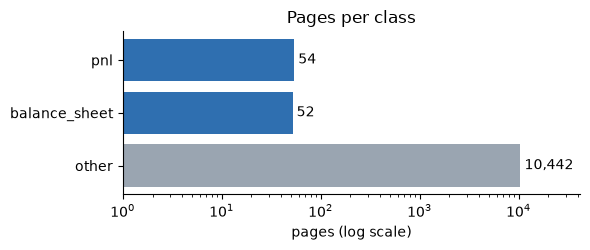

In [3]:
dist = pages.label.value_counts().reindex(T.LABELS)
display(pd.DataFrame({"pages": dist, "share": (100 * dist / dist.sum()).round(2).astype(str) + "%"}))

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(list(T.LABELS)[::-1], dist[::-1], color=["#9aa5b1", "#2f6fb0", "#2f6fb0"])
ax.set_xscale("log")
ax.set_xlabel("pages (log scale)")
for i, v in enumerate(dist[::-1]):
    ax.text(v * 1.1, i, f"{v:,}", va="center")
ax.set_xlim(1, dist.max() * 4)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Pages per class")
plt.tight_layout(); plt.show()

## 3. Train / test split by **company**, not by page

Reports from the same company reuse the same page layout year after year. If pages from one company landed in both training and test, the model could memorise that company's template and the test score would overstate how well it handles a new company.

So every company sits entirely on one side. The **test set is five companies the model never sees in training**: two banks (Banking Regulation Act format) and three NBFC / housing-finance companies (Ind AS format). Related entities are kept together (Kotak Mahindra Bank with Kotak Mahindra Investments; Bajaj Finance with Bajaj Housing Finance). Two training companies are also held back during training to choose when to stop (`validation`).

In [4]:
role = {c: "validation" for c in T.VAL_COMPANIES}
table = (pages.assign(role=lambda d: np.where(d.split == "test", "TEST", d.company.map(role).fillna("train")))
              .pivot_table(index=["role", "company"], columns="label", values="page_number", aggfunc="count", fill_value=0)
              .reindex(columns=list(T.LABELS)))
table.insert(0, "reports", pages.groupby(["company"]).source_file.nunique().reindex(table.index.get_level_values(1)).values)
table = table.sort_index(level=0, key=lambda s: s.map({"train": 0, "validation": 1, "TEST": 2}))
display(table)

assert not set(train.company) & set(test.company), "a company appears in both train and test"
for name, part in [("train (incl. validation)", train), ("TEST", test)]:
    c = part.label.value_counts()
    print(f"{name:<25} {part.company.nunique():>2} companies  {len(part):>5,} pages   pnl={c.get('pnl', 0)}  balance_sheet={c.get('balance_sheet', 0)}")

label                           reports  pnl  balance_sheet  other
role       company                                                
train      Axis Bank                  1    2              2    500
           Can Fin Homes              1    1              1    354
           IndusInd Bank              1    2              3    411
           Kotak group                8   13             13   2545
           L&T Finance                3    9              9   1932
           LIC Housing Finance        3    8              6   1161
validation Bajaj group                2    6              6    713
           HDFC Bank                  1    2              2    586
TEST       ICICI Bank                 1    2              2    337
           Muthoot Finance            1    2              2    418
           PNB Housing Finance        1    2              2    421
           Shriram Finance            1    3              2    551
           State Bank of India        1    2              2    513

train (incl. validation)   8 companies  8,287 pages   pnl=43  balance_sheet=42
TEST                       5 companies  2,261 pages   pnl=11  balance_sheet=10


## 4. How the labels were made

Hand-labelling 10,000+ pages was not practical, so labels were **bootstrapped** from rules and then **checked by hand where it matters**:

1. **Rules (all pages).** A page is a statement if it carries a statement title from the app's existing keyword list *and* the line items a real statement always has (e.g. total assets, equity share capital, other equity, cash, borrowings for a balance sheet). Requiring line items stops notes that merely *mention* "balance sheet" from being labelled. Extra rules catch statements split over two pages and pages whose title is an image.
2. **Hand verification (test set).** Every test page labelled as a statement, plus every test page that looked like a possible miss, was reviewed by a person: 61 pages. Two labels were corrected. These verified labels are stored in `ann/test_labels.csv` (file name, page, label; no text) and pin the test set.

Training labels were not hand-checked, so they contain a little noise (two LIC tax notes are labelled `pnl`).

In [5]:
verified = pd.read_csv(ANN / "test_labels.csv")
print(f"Hand-verified test pages: {len(verified)}  ->  " + ", ".join(f"{k}={v}" for k, v in verified.label.value_counts().items()))
print("Pages not listed are 'other'.\n")

corrected = test[test.label != test.auto_label][["company", "page_number", "auto_label", "label"]]
print("Rule labels corrected by hand:")
display(corrected.rename(columns={"auto_label": "rule label", "label": "verified label"}).reset_index(drop=True))

Hand-verified test pages: 61  ->  other=40, pnl=11, balance_sheet=10
Pages not listed are 'other'.

Rule labels corrected by hand:


,company,page_number,rule label,verified label
0,Shriram Finance,390,other,pnl
1,Shriram Finance,470,pnl,other


## 5. The network

Deliberately small and explainable:

1. **TF-IDF** turns each page into 5,000 numbers: one per informative word, weighted up when the word is frequent on this page but rare across pages ("other equity", "interest expended", "total assets" score high on statements).
2. A **multi-layer perceptron** reads those numbers: two hidden layers (256 and 128 units, ReLU) with 30% dropout against over-fitting, and a 3-way softmax output giving a probability per class.
3. Loss: categorical cross-entropy; optimiser: Adam.

In [6]:
T.build_model(T.MAX_FEATURES).summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │     1,280,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,313,539 (5.01 MB)

 Trainable params: 1,313,539 (5.01 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Training

* **Class weights** make each class count equally in the loss: a missed statement page costs about 200× more than a misread `other` page.
* **Phase 1** trains on six training companies and, after every epoch, measures the F1 score for `pnl` and `balance_sheet` on the two validation companies; the best epoch is kept.
* **Phase 2** retrains from scratch on all eight training companies for that number of epochs (statement pages are scarce, so the validation pages are worth adding back).
* The test companies are used exactly once, at the end.

In [7]:
if RETRAIN:
    subprocess.run([sys.executable, str(ANN / "train.py")], check=True, cwd=ROOT)

history = json.loads((MODEL / "history.json").read_text())
fit_labels = T.encode(train[~train.company.isin(T.VAL_COMPANIES)].label)
print("Class weights:", {T.LABELS[k]: round(v, 2) for k, v in T.class_weights(fit_labels).items()})
print("Validation companies:", ", ".join(history["val_companies"]))
print(f"Best epoch on validation: {history['best_epoch']} of {len(history['phase1_val_statement_f1'])} run")

Class weights: {'pnl': 66.4, 'balance_sheet': 68.35, 'other': 0.34}
Validation companies: Bajaj group, HDFC Bank
Best epoch on validation: 8 of 16 run


## 7. Training curve

Left and middle: the loss falls on the training companies and on the unseen validation companies. Right: the score we actually care about on the validation companies. It is **jumpy**, because the two validation companies have only 16 statement pages between them, so one page more or less moves it a lot. Epoch 8 was chosen by that score; reassuringly, the validation loss (middle) also reaches its lowest point at epoch 8 and rises afterwards as the network starts to over-fit. Even so, a choice resting on 16 pages is one of the limitations noted at the end.

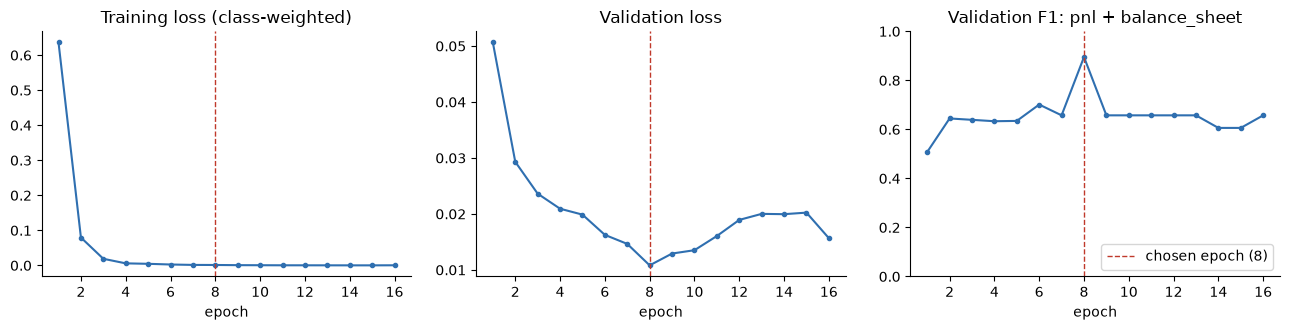

In [8]:
ep = np.arange(1, len(history["phase1_val_statement_f1"]) + 1)
best = history["best_epoch"]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
panels = [("phase1_train_loss_weighted", "Training loss (class-weighted)"),
          ("phase1_val_loss", "Validation loss"),
          ("phase1_val_statement_f1", "Validation F1: pnl + balance_sheet")]
for ax, (key, title) in zip(axes, panels):
    ax.plot(ep, history[key], marker="o", ms=3, color="#2f6fb0")
    ax.axvline(best, color="#c0392b", ls="--", lw=1, label=f"chosen epoch ({best})")
    ax.set_title(title); ax.set_xlabel("epoch")
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.spines[["top", "right"]].set_visible(False)
axes[2].set_ylim(0, 1); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

## 8. Results on the five held-out test companies

The saved model (`page_classifier_slim.keras`, prediction-only) and vectorizer (`tfidf.pkl`) are loaded and run once on the test companies.

* **Precision:** of the pages the model called a P&L (or balance sheet), how many really were.
* **Recall:** of the real P&L (or balance sheet) pages, how many the model found.
* **F1:** a single score balancing the two.

In [9]:
model = keras.models.load_model(MODEL / "page_classifier_slim.keras")
with open(MODEL / "tfidf.pkl", "rb") as fh:
    vectorizer = pickle.load(fh)

y_true = T.encode(test.label)
y_pred = model.predict(vectorizer.transform(test.page_text).toarray(), verbose=0).argmax(axis=1)

rep = classification_report(y_true, y_pred, labels=[0, 1, 2], target_names=T.LABELS, output_dict=True, zero_division=0)
metrics = pd.DataFrame(rep).T.loc[list(T.LABELS), ["precision", "recall", "f1-score", "support"]]
metrics["support"] = metrics["support"].astype(int)
display(metrics.style.format({"precision": "{:.3f}", "recall": "{:.3f}", "f1-score": "{:.3f}"}))

statement_f1 = T.statement_f1(y_true, y_pred)
base = (y_true == T.LABELS.index("other")).mean()
print(f"Statement F1 (average of pnl and balance_sheet): {statement_f1:.3f}")
print(f"Accuracy: {accuracy_score(y_true, y_pred):.2%}   <- not meaningful on its own: answering 'other' for every page "
      f"would already score {base:.2%} while finding no statements.")

# same numbers as the training run's report
assert f"Statement macro F1 (pnl, balance_sheet): {statement_f1:.3f}" in (MODEL / "metrics.txt").read_text(encoding="utf-8")

,precision,recall,f1-score,support
pnl,1.000,0.818,0.900,11
balance_sheet,0.889,0.800,0.842,10
other,0.998,1.000,0.999,2240


Statement F1 (average of pnl and balance_sheet): 0.871
Accuracy: 99.78%   <- not meaningful on its own: answering 'other' for every page would already score 99.07% while finding no statements.


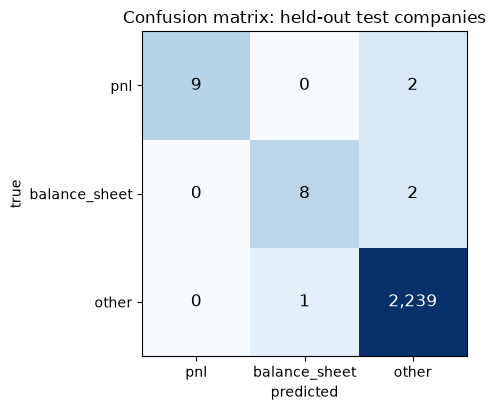

In [10]:
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow(np.log1p(cm), cmap="Blues")   # log colour scale so the small cells stay visible
for i in range(3):
    for j in range(3):
        ax.text(j, i, f"{cm[i, j]:,}", ha="center", va="center", fontsize=12,
                color="white" if cm[i, j] > cm.max() / 4 else "black")
ax.set_xticks(range(3), T.LABELS); ax.set_yticks(range(3), T.LABELS)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title("Confusion matrix: held-out test companies")
plt.tight_layout(); plt.show()

## 9. Compared with the existing keyword rules

The app currently finds statement pages with hand-written keyword rules. Run on the same test pages, those rules (strengthened with the line-item checks above) score **higher** than the network.

**That comparison is biased in the rules' favour.** The test labels were produced by those same rules and then checked by hand, so the rules can only be wrong where a reviewer corrected them (2 pages). A statement that both the rules and the reviewer missed would count against neither. The network, by contrast, is scored against labels it had no part in making. The fair reading: on companies it has never seen, the network finds most statement pages with almost no false alarms, but it does not yet beat the rules.

In [11]:
y_rule = T.encode(test.auto_label)
def f1s(pred):
    r = classification_report(y_true, pred, labels=[0, 1, 2], target_names=T.LABELS, output_dict=True, zero_division=0)
    return [r["pnl"]["f1-score"], r["balance_sheet"]["f1-score"], T.statement_f1(y_true, pred)]
comparison = pd.DataFrame([f1s(y_pred), f1s(y_rule)], index=["neural network", "keyword + line-item rules*"],
                          columns=["pnl F1", "balance_sheet F1", "statement F1"])
display(comparison.style.format("{:.3f}"))
print("* biased upward: the test labels started from these rules (see above).")

,pnl F1,balance_sheet F1,statement F1
neural network,0.900,0.842,0.871
keyword + line-item rules*,0.909,1.000,0.955


* biased upward: the test labels started from these rules (see above).


## 10. Where the network goes wrong

Every test error is listed (company and page only). Four real statements were missed, three of them from one bank (ICICI); one note about the assets and liabilities of discontinued operations was mistaken for a balance sheet. These were deliberately not tuned away: the test set is for measuring, not for fitting.

In [12]:
errors = test.assign(predicted=[T.LABELS[i] for i in y_pred]).query("label != predicted").sort_values(["company", "page_number"])
display(errors[["company", "page_number", "label", "predicted"]].rename(columns={"label": "true"}).reset_index(drop=True))

,company,page_number,true,predicted
0,ICICI Bank,147,balance_sheet,other
1,ICICI Bank,265,balance_sheet,other
2,ICICI Bank,266,pnl,other
3,Muthoot Finance,303,pnl,other
4,Shriram Finance,471,other,balance_sheet


## 11. Limitations and next steps

**Limitations**
* **Small data.** About 70 unique statement pages to learn from (85 labelled, some overlapping across Kotak's reports) and 21 to test on. With 21 test pages, a single error moves recall by 5–10 points, so the scores above are rough.
* **Fragile stopping point.** The validation score jumps around between epochs (section 7); the chosen epoch rests on 16 validation statement pages, although validation loss agrees with it.
* **Bootstrapped labels.** Training labels come from rules, so the network partly learns to imitate them, including their few mistakes. Only the test set is hand-verified.
* **Scope.** Annual reports only; investor presentations are out of scope and keep using the keyword logic.

**Next steps**
* **More annual reports** from more banks and NBFCs: the single biggest lever. Each report adds roughly four statement pages and a new layout.
* Repeat the evaluation with several different test-company groups (cross-validation by company) to get error bars instead of a single score.
* Integrate into the app as an optional second opinion, with the keyword rules as fallback, and as a pre-flight check that rejects uploads with no statement pages.